# Employee Attrition Analysis

Why are employees leaving, and who is likely to leave next? This notebook explores 14,999 HR records, segments departed employees with K-Means clustering, and compares three classifiers (Logistic Regression, Random Forest, Gradient Boosting) to flag at-risk employees for targeted retention.

## Data

In [1]:
# Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Read in CSV
df = pd.read_csv('HR_comma_sep.csv')

# Check the first few rows of the dataframe
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [3]:
# Renaming sales column to department
df.rename(columns={'sales': 'department'}, inplace=True)

#Check the last few rows of the dataframe
df.tail()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low
14998,0.37,0.52,2,158,3,0,1,0,support,low


In [4]:
# Check the shape of the dataframe
df.shape

(14999, 10)

In [5]:
# Check the data types of the dataframe
df.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
department                object
salary                    object
dtype: object

In [6]:
# Check for missing values
df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

## Understand what factors contributed most to employee turnover at EDA

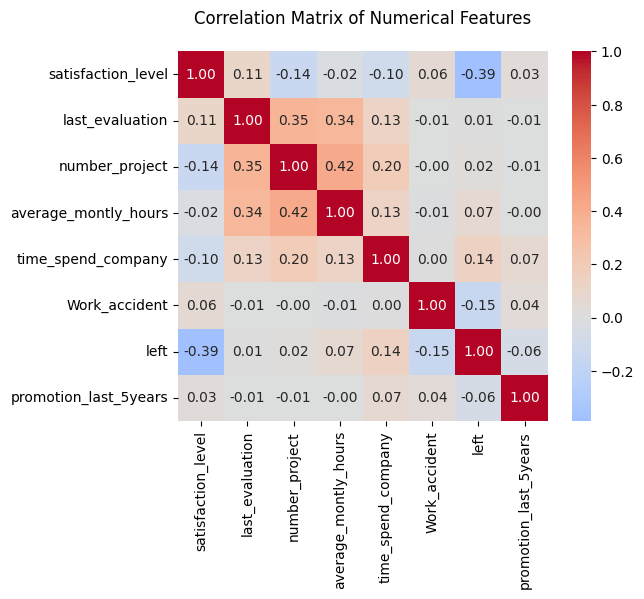

In [7]:
# Draw a heatmap of the correlation matrix between all numerical features or columns in the data

correlation_matrix = df.select_dtypes(include=['int64', 'float64']).corr()

plt.title('Correlation Matrix of Numerical Features', pad=20)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f',square=True)

plt.show() 

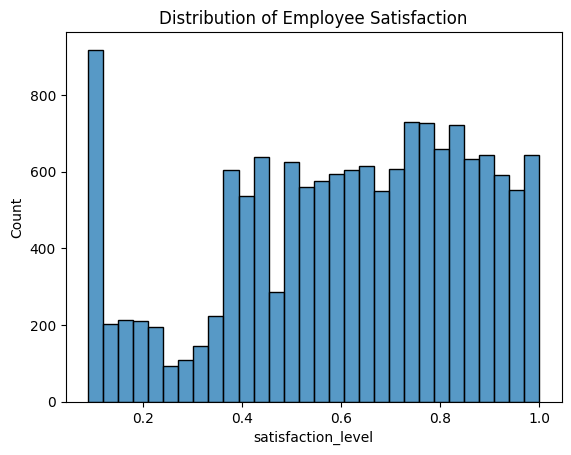

In [8]:
# Draw the distribution plot of Employee Satisfaction
plt.title('Distribution of Employee Satisfaction')
sns.histplot(data=df, x='satisfaction_level')

plt.show()

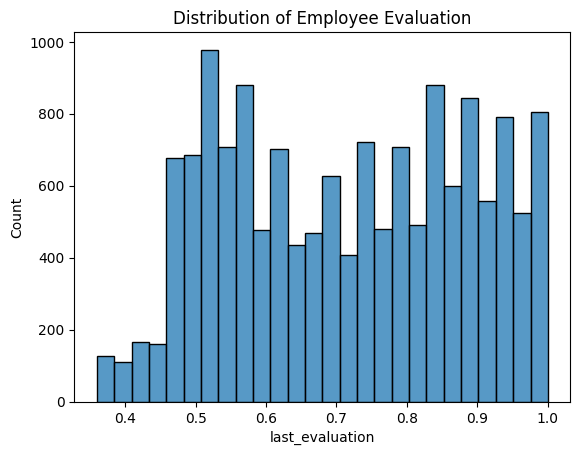

In [9]:
# Draw the distribution plot of Employee Evaluation
plt.title('Distribution of Employee Evaluation')
sns.histplot(data=df, x='last_evaluation')

plt.show()

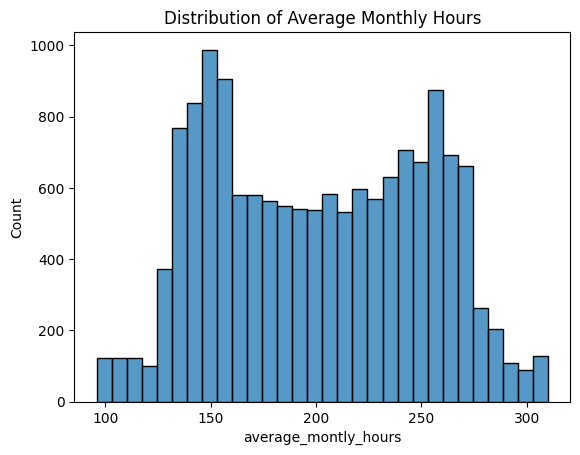

In [10]:
# Draw the distribution plot of Average Monthly Hours
plt.title('Distribution of Average Monthly Hours')
sns.histplot(data=df, x='average_montly_hours')

plt.show()

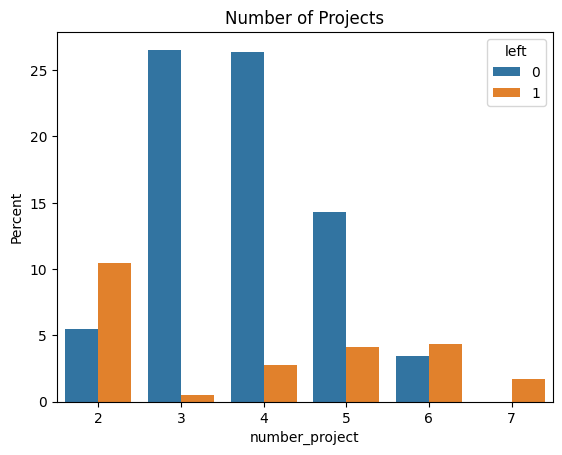

In [11]:

# Draw the bar plot of Number of Projects
plt.title('Number of Projects')
sns.barplot(data=df, x='number_project', y='number_project', hue='left', estimator=lambda x: len(x) / len(df) * 100) # lamda function to calculate the percentage of left employees

plt.ylabel('Percent')
plt.show()

Employees with 2, 6, and 7 projects are more likely to leave, while employees with 3-5 projects are more likely to stay

Perhaps employees with more than 6 projects feel overworked and are inclined to leave
Perhaps employees with less than 3 projects feel underworked and potentially undervalued and are inclined to leave

## Perform clustering of employees who left based on their satisfaction and evaluation

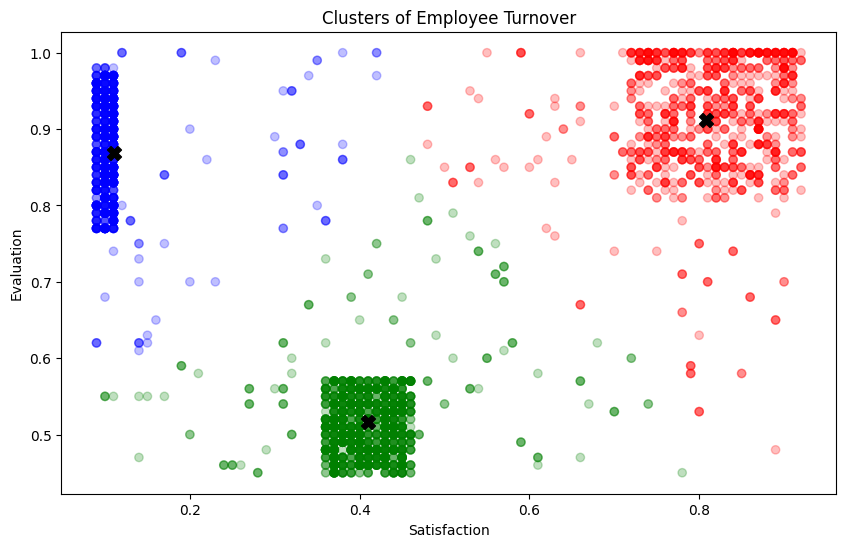

In [12]:
# Import KMeans Model
from sklearn.cluster import KMeans

# Graph and create 3 clusters of Employee Turnover
kmeans = KMeans(n_clusters=3,random_state=2)
kmeans.fit(df[df.left==1][["satisfaction_level","last_evaluation"]])

kmeans_colors = ['green' if c == 0 else 'blue' if c == 2 else 'red' for c in kmeans.labels_]

fig = plt.figure(figsize=(10, 6))
plt.scatter(x="satisfaction_level",y="last_evaluation", data=df[df.left==1],alpha=0.25,color = kmeans_colors)
plt.xlabel("Satisfaction")
plt.ylabel("Evaluation")
plt.scatter(x=kmeans.cluster_centers_[:,0],y=kmeans.cluster_centers_[:,1],color="black",marker="X",s=100)
plt.title("Clusters of Employee Turnover")
plt.show()

Blue: High Evaluation, Low Satisfaction - Good and sad worker
Green: Low Evaluation, Low-Medium Satisfaction - Bad and sad worker
Red: High Evaluation, High Satisfaction - Good and happy worker


Blue: Unmet needs, lack of growth opportunities, work-life imbalance, unhappy with management or work culture, etc
Green: Performance issues, unfit for role, lack of support
Red: Ideal employee, unprecedented circumstances, outbid (got another offer too good to refuse), hidden dissatisfaction, life changes

## Handle the `left` class imbalance using SMOTE (training data only)

The data is split **before** oversampling so the test set contains only real employees the models have never seen. SMOTE is then applied to the training set only.

In [13]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

# Separating categorical variables and numeric variables 
# Create dummy variables for the 'department' and 'salary' features, since they are categorical 
department = pd.get_dummies(data=df['department'],drop_first=True,prefix='dep', dtype=int) #drop first column to avoid dummy trap
salary = pd.get_dummies(data=df['salary'],drop_first=True,prefix='sal', dtype=int)
df.drop(['department','salary'],axis=1,inplace=True)
df = pd.concat([df,department,salary],axis=1)


In [14]:
from imblearn.over_sampling import SMOTE

# Create train and test splits
X = df.drop('left', axis=1)
y = df['left']

# Split BEFORE oversampling so the test set contains only real, unseen employees
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=123, stratify=y)

# Apply SMOTE to the training data only
smote = SMOTE(random_state=123)
X_train_up, y_train_up = smote.fit_resample(X_train, y_train)

print('Training set before SMOTE:', y_train.value_counts().to_dict())
print('Training set after SMOTE: ', y_train_up.value_counts().to_dict())
print('Test set (untouched):     ', y_test.value_counts().to_dict())

Training set before SMOTE: {0: 9142, 1: 2857}
Training set after SMOTE:  {0: 9142, 1: 9142}
Test set (untouched):      {0: 2286, 1: 714}


## Perform 5-fold cross-validation model training and evaluate performance

Cross-validation uses an `imblearn` pipeline so SMOTE runs inside each fold; validation folds only ever contain real employees.

In [15]:
# Train the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000)

# Train the model
log_reg.fit(X_train_up, y_train_up)

# Make predictions
log_y_pred = log_reg.predict(X_test)
print('Logistic Regression Model Accuracy: ', accuracy_score(y_test, log_y_pred))



Logistic Regression Model Accuracy:  0.752


In [16]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

# 5 fold CV to train Logistic Regression Model

kfold = StratifiedKFold(n_splits=5, random_state=123, shuffle=True)
log_cv = Pipeline([('smote', SMOTE(random_state=123)), ('model', LogisticRegression(max_iter=1000))])
scoring = 'roc_auc'

# Print Results
results = cross_val_score(log_cv, X_train, y_train, cv=kfold, scoring=scoring)
log_roc_auc = results.mean(), results.std()
print("AUC: %.3f (%.3f)" % log_roc_auc)

# Print the classification report
print(classification_report(y_test, log_y_pred))


AUC: 0.809 (0.006)
              precision    recall  f1-score   support

           0       0.91      0.75      0.82      2286
           1       0.49      0.75      0.59       714

    accuracy                           0.75      3000
   macro avg       0.70      0.75      0.71      3000
weighted avg       0.81      0.75      0.77      3000



In [17]:
from sklearn.ensemble import RandomForestClassifier

# Train the Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=123)
rf_model.fit(X_train_up, y_train_up)

# Make predictions
rf_y_pred = rf_model.predict(X_test)
print('Random Forest Model Accuracy: ', accuracy_score(y_test, rf_y_pred))

Random Forest Model Accuracy:  0.9883333333333333


In [18]:
# 5 fold CV to train Random Forest Model

kfold = StratifiedKFold(n_splits=5, random_state=123, shuffle=True)
rf_cv = Pipeline([('smote', SMOTE(random_state=123)), ('model', RandomForestClassifier(n_estimators=100, random_state=123))])
scoring = 'roc_auc'

# Print Results
results = cross_val_score(rf_cv, X_train, y_train, cv=kfold, scoring=scoring)
rf_roc_auc = results.mean(), results.std()
print("AUC: %.3f (%.3f)" % rf_roc_auc)

# Print the classification report
print(classification_report(y_test, rf_y_pred))


AUC: 0.991 (0.003)
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2286
           1       0.97      0.98      0.98       714

    accuracy                           0.99      3000
   macro avg       0.98      0.99      0.98      3000
weighted avg       0.99      0.99      0.99      3000



In [19]:
from sklearn.ensemble import GradientBoostingClassifier

# Train the Gradient Boosting Model
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=123)
gb_model.fit(X_train_up, y_train_up)

# Make predictions
gb_y_pred = gb_model.predict(X_test)
print('Gradient Boosting Model Accuracy: ', accuracy_score(y_test, gb_y_pred)) 


Gradient Boosting Model Accuracy:  0.9633333333333334


In [20]:
# 5 fold CV to train Gradient Boosting Model

kfold = StratifiedKFold(n_splits=5, random_state=123, shuffle=True)
gb_cv = Pipeline([('smote', SMOTE(random_state=123)), ('model', GradientBoostingClassifier(n_estimators=100, random_state=123))])
scoring = 'roc_auc'

# Print Results 
results = cross_val_score(gb_cv, X_train, y_train, cv=kfold, scoring=scoring)
gb_roc_auc = results.mean(), results.std()
print("AUC: %.3f (%.3f)" % gb_roc_auc)

# Print the classification report
print(classification_report(y_test, gb_y_pred))


AUC: 0.988 (0.003)
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      2286
           1       0.91      0.94      0.92       714

    accuracy                           0.96      3000
   macro avg       0.95      0.95      0.95      3000
weighted avg       0.96      0.96      0.96      3000



## Identify the best model and justify the evaluation metrics used

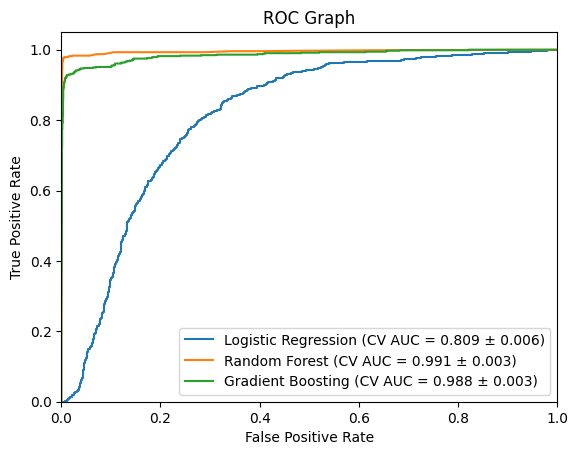

In [21]:
from sklearn.metrics import roc_curve
# Plot ROC Graph
fpr, tpr, thresholds = roc_curve(y_test, log_reg.predict_proba(X_test)[:,1])
rf_fpr, rf_tpr, rf_thresholds = roc_curve(y_test, rf_model.predict_proba(X_test)[:,1])
gb_fpr, gb_tpr, gb_thresholds = roc_curve(y_test, gb_model.predict_proba(X_test)[:,1])


plt.figure()

# Plot Logistic Regression ROC
plt.plot(fpr, tpr, label='Logistic Regression (CV AUC = %0.3f ± %.3f)' % log_roc_auc)

# Plot Random Forest ROC
plt.plot(rf_fpr, rf_tpr, label='Random Forest (CV AUC = %0.3f ± %.3f)' % rf_roc_auc)

# Plot Gradient Boosting ROC
plt.plot(gb_fpr, gb_tpr, label='Gradient Boosting (CV AUC = %0.3f ± %.3f)' % gb_roc_auc)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Graph')
plt.legend(loc="lower right")
plt.show()


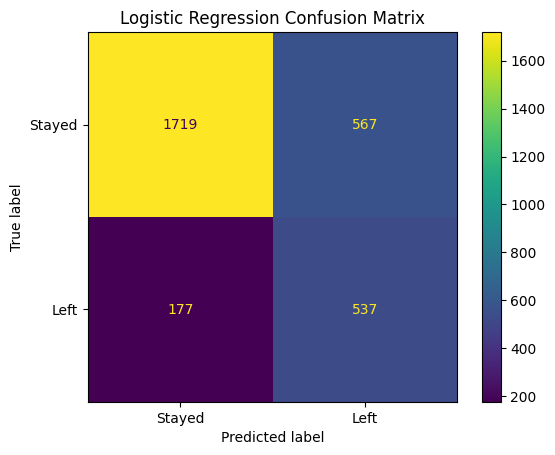

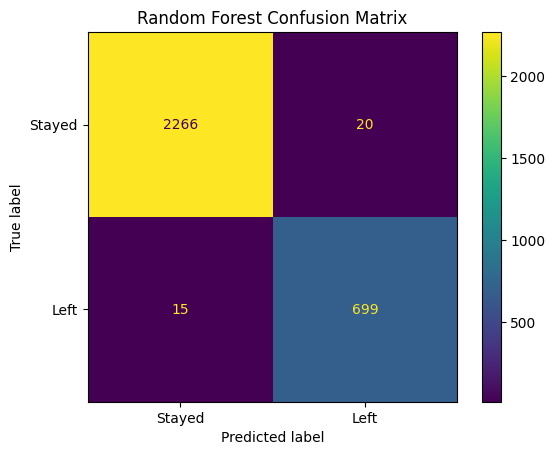

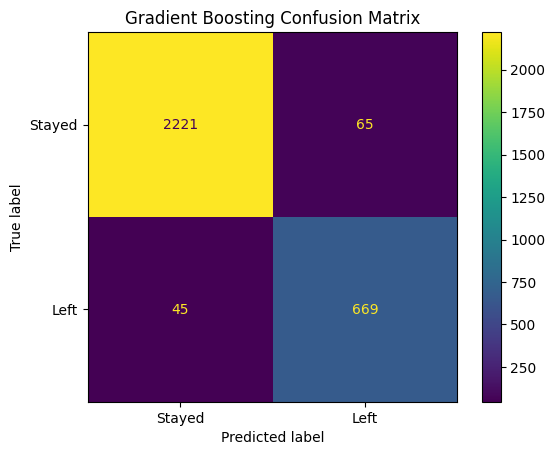

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Plot confusion matrix for Logistic Regression Model

log_cm = confusion_matrix(y_test, log_y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=log_cm, display_labels=["Stayed", "Left"])
cm_display.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show() 
# Plot confusion matrix for Random Forest Model

rf_cm = confusion_matrix(y_test, rf_y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=["Stayed", "Left"])
cm_display.plot()
plt.title("Random Forest Confusion Matrix")
plt.show() 
# Plot confusion matrix for Gradient Boosting Model

gb_cm = confusion_matrix(y_test, gb_y_pred) 
cm_display = ConfusionMatrixDisplay(confusion_matrix=gb_cm, display_labels=["Stayed", "Left"])
cm_display.plot()
plt.title("Gradient Boosting Confusion Matrix")
plt.show()

### Results on the held-out test set (3,000 real employees, 714 who left)

| Model | Accuracy | Recall (Left) | Precision (Left) | 5-fold CV AUC |
|---|---|---|---|---|
| Logistic Regression | 75.2% | 0.75 | 0.49 | 0.809 ± 0.006 |
| **Random Forest** | **98.8%** | **0.98** | **0.97** | **0.991 ± 0.003** |
| Gradient Boosting | 96.3% | 0.94 | 0.91 | 0.988 ± 0.003 |

Random Forest is the best model: it correctly flags 699 of the 714 employees who left while raising only 20 false alarms.

A false positive would be predicting that an employee left when they actually end up staying
A false negative would be predicting that an employee stays when they actually end up leaving

The main goal is to incentivize employees that would have left into staying, the more costly outcome with that in mind would be a false negative.
Therefore, we should prioritize recalls as we want to minimize failing to identify a positive case where the employee is highly likely to leave


## Suggest various retention strategies for targeted employees

Employee Turnover Risk Zone Counts: Risk_Category
Safe           2157
High-Risk       648
Low-Risk        136
Medium-Risk      59
Name: count, dtype: int64


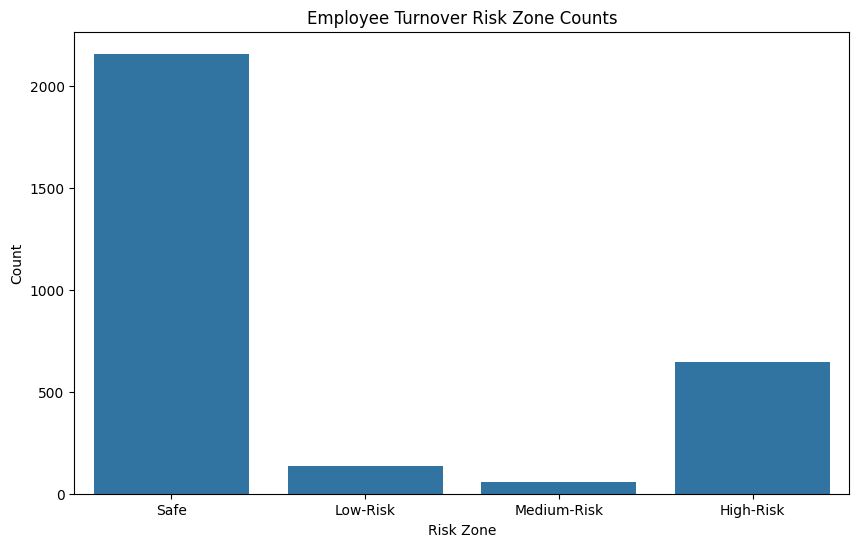

In [23]:
# Using the best model, predict the probability of employee turnover in the test data

rf_y_pred_proba = rf_model.predict_proba(X_test)[:,1]

# Creating a dataframe with the predicted probabilities
risk_df = pd.DataFrame({'Employee_ID': X_test.index, 'Risk': rf_y_pred_proba})

# Categorize the risk into Safe, Low-Risk, Medium-Risk, High-Risk
risk_df['Risk_Category'] = pd.cut(risk_df['Risk'], bins=[-0.1, 0.2, 0.6, 0.9, 1.0], labels=['Safe', 'Low-Risk', 'Medium-Risk', 'High-Risk'])

risk_zone_counts = risk_df['Risk_Category'].value_counts()

print(f'Employee Turnover Risk Zone Counts: {risk_zone_counts}')

# Plot the risk zone counts
plt.figure(figsize=(10, 6))
sns.barplot(x=risk_zone_counts.index, y=risk_zone_counts.values)
plt.title('Employee Turnover Risk Zone Counts')
plt.xlabel('Risk Zone')
plt.ylabel('Count')
plt.show()


Potential Retention Strategies For each risk zone:

Safe:
- Continue with current retention efforts
- Monitor for any potential issues

Low-Risk:
- Continue with current retention efforts
- Monitor for any potential issues

Medium-Risk:
- Offer additional support or resources
- Schedule regular check-ins
- Provide training or development opportunities
- Recognize and reward achievements

High-Risk:
- Offer a retention bonus or special incentives
- Provide additional resources or support
- Explore flexible work arrangements
- Offer career development opportunities
- Address specific concerns or issues   


Overall:
- Improve exit interviews
- Develop targetted retention strategies for medium-high risk employees
- Enhance employee engagement
- Review HR processes
